# Fraud detection with a Decision Tree: Gini vs. Entropy

Data: same 59,940 synthetic card payments, about 2.7% fraud (based on Stripe's fraud primer).

A decision tree asks yes/no questions. At each step it picks the question that makes the groups **least mixed**.
"Mixed" is measured by an **impurity** score, and you choose which one with a single option:

```python
DecisionTreeClassifier(criterion="gini")      # or criterion="entropy"
```

**Plan:** (1) Gini by hand → (2) gain by hand → (3) the real first question → (4) train → (5) evaluate → (6) Gini vs. entropy.

There are **5 questions**. Replace `"?"` with your answer and run the cell.

In [1]:
CRITERION = "gini"     # try "gini", then "entropy"
MAX_DEPTH = 6

import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, average_precision_score
from tree_lab import gini, entropy, split_gain, load_data, make_X_y, time_split
from quiz import check

## 1. Gini impurity by hand

For a group of payments where a share $p$ is fraud:

$$\text{Gini} = 1 - p^2 - (1-p)^2$$

It is **0** when the group is pure (all fraud or all legit) and **0.5** at most (a 50/50 mix).

**Example:** a group of 10 payments, 3 of them fraud, so $p = 0.3$.

In [12]:
# Q1 - Gini of this group (2 decimals)
check("Q1", "0.42")

Q1: ✅ correct  (you answered 0.42)


## 3. The first question

The tree does the same calculation on all 39,960 training payments, for every feature and threshold, and keeps the biggest gain.
Here are three candidates:

* A) `amount ≤ 4.01`: a tiny payment
* B) `amount_vs_merchant_avg ≤ 0.15`: tiny compared with what this shop normally sells
* C) `country_mismatch == 1`: IP country differs from the card's country

In [13]:
# Q2 - read the running output in the below cellwhich one has the biggest GINI gain? (A, B or C)
check("Q3", "B")

Q3: ✅ correct  (you answered B)


In [4]:
df = load_data()
train = df[df.day < 60]
y = train.is_fraud

candidates = {"A) amount <= 4.01": train.amount <= 4.01,
              "B) amount_vs_merchant_avg <= 0.15": train.amount_vs_merchant_avg <= 0.15,
              "C) country_mismatch == 1": train.country_mismatch == 1}
pd.DataFrame({"gini_gain": {k: split_gain(y, v, "gini") for k, v in candidates.items()},
              "entropy_gain": {k: split_gain(y, v, "entropy") for k, v in candidates.items()}}).round(4)

,gini_gain,entropy_gain
A) amount <= 4.01,0.0116,0.0352
B) amount_vs_merchant_avg <= 0.15,0.0118,0.0336
C) country_mismatch == 1,0.0054,0.0320


## 4. Train the tree

remember, always split the data in to at least train and test, in this case, we go further, do train-val-test split.Train on days 0-59, check settings on days 60-74, test on days 75-89 (the "future").

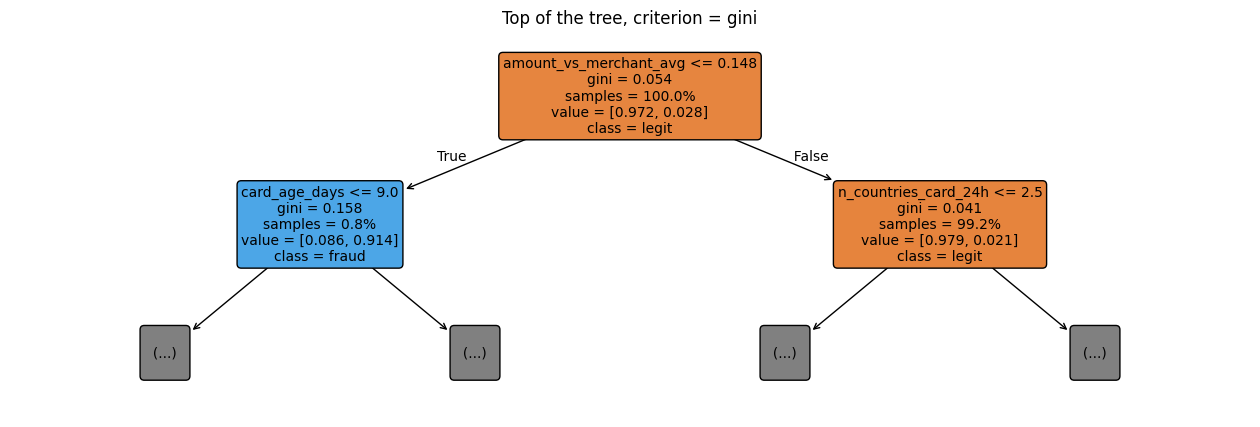

In [5]:
X, y_all = make_X_y(df)
X_train, y_train, X_valid, y_valid, X_test, y_test = time_split(df, X, y_all)

tree = DecisionTreeClassifier(criterion=CRITERION, max_depth=MAX_DEPTH, min_samples_leaf=20, random_state=42)
tree.fit(X_train, y_train)

plt.figure(figsize=(16, 5))
plot_tree(tree, feature_names=list(X.columns), class_names=["legit", "fraud"], max_depth=1,
          filled=True, impurity=True, proportion=True, rounded=True, fontsize=10)
plt.title(f"Top of the tree, criterion = {CRITERION}"); plt.show()

## 5. Evaluate

Fraud is rare, so **accuracy is misleading**: a model that never flags anything is already ~97.6% accurate.
Instead we look at the confusion matrix:

| | predicted legit | predicted fraud |
|---|---|---|
| **actually legit** | TN | FP (good customer blocked) |
| **actually fraud** | FN (fraud missed) | TP (fraud caught) |

* **Precision** = TP / (TP + FP): of the payments we flagged, what share was fraud?
* **Recall** = TP / (TP + FN): of all the fraud, what share did we catch?

**Practice:** If TP = 150, FP = 50, FN = 100, TN = 9,700. then calculate for Q3 and Q4 applying the above equations

In [14]:
# Q3 - precision (2 decimals)
check("Q4", "0.75")

Q4: ✅ correct  (you answered 0.75)


In [15]:
#  Q4 - recall (2 decimals)
check("Q5", "0.60")

Q5: ✅ correct  (you answered 0.60)


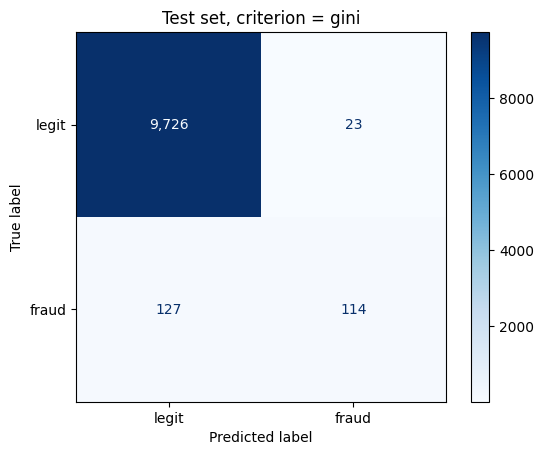

accuracy  0.985   (never-fraud model: 0.976)
precision 0.832
recall    0.473


In [8]:
test_pred = tree.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["legit", "fraud"],
                                        cmap="Blues", values_format=",")
plt.title(f"Test set, criterion = {CRITERION}"); plt.show()

print(f"accuracy  {(test_pred == y_test).mean():.3f}   (never-fraud model: {1 - y_test.mean():.3f})")
print(f"precision {precision_score(y_test, test_pred):.3f}")
print(f"recall    {recall_score(y_test, test_pred):.3f}")

## 6. Gini vs. entropy, side by side

Same data, same settings, only the criterion changes. We try several depths and score each on validation with
**PR-AUC** (area under the precision-recall curve, 1.0 = perfect; a good metric when fraud is rare).

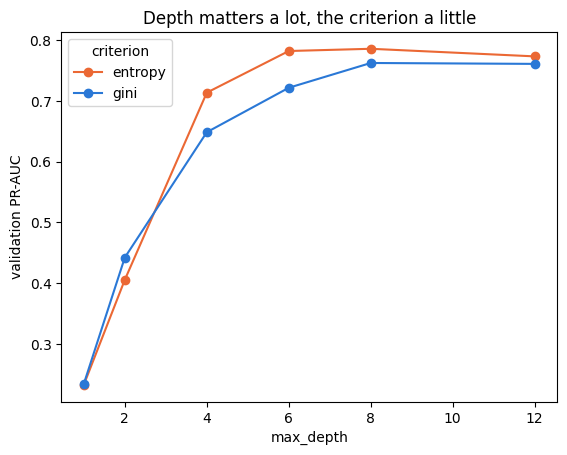

criterion,entropy,gini
max_depth,,
1,0.233,0.234
2,0.405,0.442
4,0.713,0.648
6,0.782,0.722
8,0.786,0.762
12,0.773,0.761


In [9]:
rows = []
for crit in ["gini", "entropy"]:
    for depth in [1, 2, 4, 6, 8, 12]:
        m = DecisionTreeClassifier(criterion=crit, max_depth=depth, min_samples_leaf=20, random_state=42).fit(X_train, y_train)
        rows.append({"criterion": crit, "max_depth": depth,
                     "valid_PR_AUC": average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])})
results = pd.DataFrame(rows).pivot(index="max_depth", columns="criterion", values="valid_PR_AUC")

results.plot(marker="o", color=["#eb6834", "#2a78d6"])
plt.ylabel("validation PR-AUC"); plt.title("Depth matters a lot, the criterion a little"); plt.show()
results.round(3)

In [10]:
summary = []
for crit in ["gini", "entropy"]:
    m = DecisionTreeClassifier(criterion=crit, max_depth=MAX_DEPTH, min_samples_leaf=20, random_state=42).fit(X_train, y_train)
    pred = m.predict(X_test)
    summary.append({"criterion": crit,
                    "first question": f"{X.columns[m.tree_.feature[0]]} <= {m.tree_.threshold[0]:.2f}",
                    "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                    "PR_AUC": average_precision_score(y_test, m.predict_proba(X_test)[:, 1])})
pd.DataFrame(summary).set_index("criterion").round(3)

,first question,precision,recall,PR_AUC
criterion,,,,
gini,amount_vs_merchant_avg <= 0.15,0.832,0.473,0.557
entropy,amount <= 4.01,0.919,0.519,0.612


## Takeaways

1. **Gini** = 1 − p² − (1−p)². The tree picks the question with the biggest drop in impurity (the **gain**).
2. **Gini and entropy** usually agree. Here they pick different first questions, but the final scores are close.
   Tree depth changes the results much more than the criterion does.
3. With rare fraud, judge a model by **precision and recall**, not accuracy.

In [ ]:
# HW8 Answers: 
# 1) 0.42
# 2) B 
# 3) 0.75
# 4) 0.60